# 04 · Mô hình, dò siêu tham số và đánh giá

**Mục tiêu.** So sánh 5 mô hình với 3 baseline trên kiểm định rolling-origin, chọn mô hình chính bằng một quy tắc định trước, rồi đánh giá trên test **một lần** ở cuối.

| Vai trò | Mô hình | Vì sao chọn |
|---|---|---|
| Baseline | B0 lớp đa số | Mốc thấp nhất: không cảnh báo tổ nào |
| Baseline | B1 "hôm qua trượt" | Mô phỏng cách quản đốc đang làm theo kinh nghiệm; mốc quan trọng nhất cần vượt |
| Baseline | B2 "mọi tổ finishing" | Quy tắc đơn giản từ EDA: finishing trượt gấp 2,4 lần sewing |
| Họ chính (Tuần 6–13) | Cây quyết định | Dễ giải thích thành luật "nếu… thì…"; bắt được tương tác như tổ × bộ phận |
| Họ chính (Tuần 6–13) | SVM (RBF) | Biên phi tuyến, hợp với dữ liệu nhỏ |
| Họ chính (Tuần 6–13) | Mạng nơ-ron (MLP) | Phi tuyến linh hoạt; kiểm tra xem mô hình phức tạp có giúp gì với 943 dòng không |
| Đối chứng | Hồi quy logistic | Mô hình tuyến tính, đọc được hệ số; mốc để xem phi tuyến có đáng không |
| Đối chứng | Random Forest | Tập hợp nhiều cây, giảm phương sai của một cây đơn |

Đề yêu cầu ít nhất 3 họ mô hình, trong đó ít nhất 2 họ thuộc Tuần 6–13, không tính baseline. Bài có 3 họ thuộc Tuần 6–13 (cây quyết định, SVM, MLP), cộng 2 mô hình đối chứng.

Mọi mô hình hỗ trợ đều dùng `class_weight="balanced"` để bù cho việc lớp "trượt" chỉ chiếm khoảng 27%; `MLPClassifier` của sklearn không có tuỳ chọn này.

> **Minh bạch về tập test.** Notebook chỉ đánh giá test một lần, sau khi mọi lựa chọn đã được làm trên train. Tuy vậy, trong quá trình phát triển, nhóm đã xem kết quả test của một lần chạy trước rồi mới quyết định một số sửa đổi phương pháp (cố định k = 3, thêm lăng kính sản phẩm, thêm chính sách thiệt hại kỳ vọng). Vì vậy các con số trên test có thể hơi lạc quan; nên dựa vào kết quả CV và khoảng tin cậy hơn là một con số test đơn lẻ.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # chạy được từ notebooks/ hoặc từ gốc repo
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
warnings.filterwarnings("ignore", category=FutureWarning)

from config import DATA_FILE, SEED
import plots as P

import features as F
import splits as S
import evaluate as E
import pipeline as PL
import run_all as RA        # dùng lại đúng hàm thăm dò biên và kiểm tra gần hoà của run_all.py

df = F.build_dataset(DATA_FILE)
train, test = S.split_train_test(df)
cv = S.RollingOriginByDate(n_blocks=6)

## 1. Dò siêu tham số và dự báo out-of-fold (khoảng 1–2 phút)
Cùng quy trình như `03_validation`: `GridSearchCV` trên bộ chia rolling-origin theo ngày, tiêu chí PR-AUC, pipeline được `fit` lại ở mỗi fold. Notebook chạy lại từ đầu để tự đứng được; mọi hạt giống ngẫu nhiên là 42 nên kết quả trùng với `03`.

Bảng dưới là cấu hình tốt nhất của từng mô hình ở kịch bản A. **Độ lệch chuẩn** ở đây và ở mọi bảng sau là độ lệch chuẩn mẫu qua 5 fold (chia cho n − 1). `GridSearchCV` tự tính độ lệch chuẩn bằng cách chia cho n, cho số nhỏ hơn khoảng 11%; bảng này không dùng con số đó để tránh hai con số khác nhau cho cùng một thứ.

In [2]:
sel = {s: E.select_models(train, s, cv) for s in ("A", "B")}
base_pred, base_folds = E.baseline_oof(train, cv)
best = sel["A"]["grid"].query("is_best")[["model", "params"]]
cvA = E.summarize_folds(sel["A"]["folds"])[["model", "average_precision_mean", "average_precision_std", "roc_auc_mean", "roc_auc_std"]]
best.merge(cvA, on="model").assign(model=lambda d: d.model.map(PL.MODEL_LABELS)).set_index("model").round(3)

,params,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std
model,,,,,
Cây quyết định,"{'clf__max_depth': 4, 'clf__min_samples_leaf': 10}",0.503,0.090,0.712,0.067
SVM (RBF),"{'clf__C': 0.1, 'clf__gamma': 'scale'}",0.544,0.103,0.756,0.051
Mạng nơ-ron (MLP),"{'clf__alpha': 0.1, 'clf__hidden_layer_sizes': (8,)}",0.485,0.069,0.718,0.041
Hồi quy logistic,{'clf__C': 100.0},0.493,0.100,0.727,0.025
Random Forest,"{'clf__max_depth': 4, 'clf__min_samples_leaf': 3}",0.574,0.123,0.766,0.045


**Nhận xét.**
- Random Forest có PR-AUC CV cao nhất (0,574 ± 0,123), tiếp theo là SVM (0,544 ± 0,103). Ba mô hình còn lại nằm trong khoảng 0,485–0,503.
- Các cấu hình được chọn đều đơn giản (cây và Random Forest sâu 4 tầng, SVM phạt mạnh với `C = 0,1`, MLP chỉ 8 nơ-ron), phù hợp với dữ liệu ít.
- Độ lệch chuẩn qua fold (0,07–0,12) lớn, cùng cỡ với chênh lệch giữa các mô hình. Phần lớn dao động này đến từ việc các fold có tỷ lệ trượt khác nhau (xem `03_validation`).

### Siêu tham số nằm ở biên lưới
Nếu giá trị được chọn nằm ở đầu hoặc cuối lưới, có thể giá trị tốt nhất thật nằm **ngoài** lưới. Bảng thứ nhất liệt kê các tham số chạm biên. Bảng thứ hai thử thêm **một nấc nữa về đúng phía bị chạm** (biên dưới thì thử nhỏ hơn, biên trên thì thử lớn hơn), giữ nguyên các tham số khác, để xem PR-AUC CV thay đổi bao nhiêu. Phần thăm dò chỉ để ghi chú, không thay đổi lựa chọn chính thức.

In [3]:
bd = E.grid_boundary_check({s: sel[s]["best"] for s in sel})
bd[bd.at_edge][["scenario", "model", "param", "grid", "best", "at_lower_edge", "at_upper_edge"]]

,scenario,model,param,grid,best,at_lower_edge,at_upper_edge
2,A,SVM_RBF,clf__C,"[0.1, 1.0, 10.0]",0.1,True,False
4,A,MLP,clf__hidden_layer_sizes,"[(8,), (16,), (32,), (64,), (16, 8)]","(8,)",True,False
6,A,Logistic,clf__C,"[0.01, 0.1, 1.0, 10.0, 100.0]",100.0,False,True
13,B,MLP,clf__hidden_layer_sizes,"[(8,), (16,), (32,), (64,), (16, 8)]","(64,)",False,True
14,B,MLP,clf__alpha,"[0.001, 0.01, 0.1, 1.0]",1.0,False,True
16,B,RandomForest,clf__min_samples_leaf,"[2, 3, 5, 10, 20]",2,True,False


In [4]:
probe = RA.stage_edge_probe(train, cv, sel, bd)
probe.assign(model=probe.model.map(PL.MODEL_LABELS), param=probe.param.str.replace("clf__", "")).round(3)

,scenario,model,param,edge,value_at_edge,cv_pr_auc_at_edge,value_beyond,cv_pr_auc_beyond,delta
0,A,SVM (RBF),C,lower,0.1,0.544,0.01,0.550,0.007
1,A,Mạng nơ-ron (MLP),hidden_layer_sizes,lower,"(8,)",0.485,"(4,)",0.505,0.019
2,A,Hồi quy logistic,C,upper,100.0,0.493,1000.0,0.494,0.001
3,B,Mạng nơ-ron (MLP),hidden_layer_sizes,upper,"(64,)",0.495,"(128,)",0.519,0.025
4,B,Mạng nơ-ron (MLP),alpha,upper,1.0,0.495,10.0,0.471,-0.024
5,B,Random Forest,min_samples_leaf,lower,2,0.590,1,0.588,-0.002


**Nhận xét.**
- Có 6 tham số chạm biên: 3 ở kịch bản A (SVM `C`, MLP số nơ-ron, Logistic `C`) và 3 ở kịch bản B.
- Thử thêm một nấc về đúng phía bị chạm, PR-AUC CV thay đổi rất ít: tăng nhiều nhất là MLP (+0,019 ở A với `(4,)`, +0,025 ở B với `(128,)`), SVM ở A tăng +0,007, Logistic gần như không đổi (+0,001), hai trường hợp còn lại giảm.
- Không thay đổi nào đủ để đổi thứ hạng: sau thăm dò, SVM ở A đạt 0,550 và MLP 0,505, vẫn dưới Random Forest (0,574). Lựa chọn chính thức giữ nguyên.
- Logistic gần như không đổi giữa `C = 100` và `C = 1000`, nghĩa là ở mức này mô hình gần như không còn bị phạt; mở rộng thêm không có ý nghĩa.
- Ở kịch bản A, mô hình có xu hướng tốt hơn khi **đơn giản hơn** (SVM phạt mạnh hơn, MLP nhỏ hơn), nhất quán với dữ liệu ít.

## 2. Kết quả CV (trung bình ± độ lệch chuẩn qua 5 fold)
**Đọc các chỉ số thế nào.**
- **PR-AUC** là chỉ số chính, dùng để chọn mô hình: đo chất lượng xếp hạng ở lớp "trượt", đúng với quyết định "tổ nào đáng cảnh báo nhất". Đoán bừa có PR-AUC bằng tỷ lệ trượt (đúng bằng dòng B0).
- **ROC-AUC** là chỉ số phụ, không phụ thuộc tỷ lệ trượt nên tiện so giữa các fold; 0,5 là đoán bừa.
- **F2, Recall, Precision** được tính ở **ngưỡng mặc định của `predict()`** (thường là xác suất 0,5), không phải ở chính sách thật "cảnh báo 3 tổ mỗi ngày". Chính sách thật được đánh giá ở `05_cost`. Vì vậy ba chỉ số này chỉ để tham khảo; đặc biệt MLP không có `class_weight` nên ở ngưỡng 0,5 nó đoán "trượt" ít hơn hẳn các mô hình khác, làm Recall thấp mà không có nghĩa là xếp hạng kém.

In [5]:
def fmt(df_, sc):
    """Bảng 'TB ± độ lệch chuẩn' (ddof=1, qua 5 fold) cho kịch bản sc và các baseline."""
    d = df_[df_.scenario.isin([sc, "-"])]
    out = pd.DataFrame({"mo_hinh": d.model.map(P.SHORT)})
    for m in E.METRICS:
        out[E.METRIC_LABELS[m]] = [f"{a:.3f} ± {b:.3f}" for a, b in zip(d[m + "_mean"], d[m + "_std"])]
    return out.set_index("mo_hinh")

folds = pd.concat([sel[s]["folds"] for s in sel] + [base_folds], ignore_index=True)
summ = E.summarize_folds(folds)
fmt(summ, "A")

,PR-AUC,ROC-AUC,F2,Recall,Precision
mo_hinh,,,,,
Cây quyết định,0.503 ± 0.090,0.712 ± 0.067,0.635 ± 0.106,0.700 ± 0.173,0.494 ± 0.070
SVM (RBF),0.544 ± 0.103,0.756 ± 0.051,0.587 ± 0.098,0.636 ± 0.119,0.453 ± 0.061
Mạng nơ-ron (MLP),0.485 ± 0.069,0.718 ± 0.041,0.558 ± 0.097,0.633 ± 0.225,0.458 ± 0.104
Hồi quy logistic,0.493 ± 0.100,0.727 ± 0.025,0.558 ± 0.072,0.588 ± 0.094,0.473 ± 0.050
Random Forest,0.574 ± 0.123,0.766 ± 0.045,0.580 ± 0.132,0.623 ± 0.170,0.473 ± 0.075
B0 (không cảnh báo),0.286 ± 0.083,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
B1 (hôm qua trượt),0.443 ± 0.100,0.656 ± 0.055,0.488 ± 0.090,0.486 ± 0.092,0.496 ± 0.082
B2 (mọi tổ finishing),0.455 ± 0.085,0.713 ± 0.055,0.528 ± 0.098,0.585 ± 0.128,0.401 ± 0.115


**Nhận xét (kịch bản A).**
- Cả 5 mô hình đều hơn B0 (0,286) và B1 (0,443) về PR-AUC trung bình. Nhưng cây quyết định (0,503), Logistic (0,493) và MLP (0,485) chỉ hơn B2 (0,455) khoảng 0,03–0,05, nhỏ hơn độ lệch chuẩn qua fold. Riêng Random Forest và SVM hơn baseline rõ hơn.
- ROC-AUC cho cùng thứ tự ở nhóm đầu: Random Forest 0,766, SVM 0,756; B1 chỉ 0,656.
- Nhóm F2/Recall/Precision cho thứ tự khác (ví dụ cây có F2 cao nhất, 0,635), vì chúng phụ thuộc ngưỡng 0,5 của từng mô hình. Không dùng nhóm này để chọn mô hình.

### Mô hình chính
**Quy tắc chọn, định trước:** mô hình có PR-AUC CV trung bình cao nhất ở kịch bản A, chọn chỉ trên train. Số cảnh báo mỗi ngày cố định k = 3 theo nguồn lực hỗ trợ, không chọn theo dữ liệu.

In [6]:
a = summ[(summ.scenario == "A") & summ.model.isin(PL.MODEL_NAMES)].sort_values("average_precision_mean", ascending=False)
print("Mô hình chính:", a.model.iloc[0])
a[["model", "average_precision_mean", "average_precision_std"]].round(3)

Mô hình chính: RandomForest


,model,average_precision_mean,average_precision_std
4,RandomForest,0.574,0.123
1,SVM_RBF,0.544,0.103
0,DecisionTree,0.503,0.090
3,Logistic,0.493,0.100
2,MLP,0.485,0.069


**Nhận xét.**
- Mô hình chính là **Random Forest**. Ở bảng đầu notebook, nó được xếp vào nhóm "đối chứng", nhưng điều đó không mâu thuẫn:
  - Random Forest là **tập hợp nhiều cây quyết định** (300 cây). Mỗi cây học trên một mẫu lấy lại ngẫu nhiên của dữ liệu và chỉ được xét một phần đặc trưng ở mỗi lần tách; dự báo cuối cùng là trung bình của các cây. Nhờ vậy nó giữ được ưu điểm của cây (bắt tương tác, không nhạy với ngoại lai, không cần chuẩn hoá) nhưng ít dao động hơn một cây đơn.
  - Yêu cầu "ít nhất 2 họ thuộc Tuần 6–13" đã được đáp ứng bởi cây quyết định, SVM và MLP; Random Forest không cần được tính vào đó. Nó được đưa vào để xem việc kết hợp nhiều cây có cải thiện so với một cây hay không, và câu trả lời là có (0,574 so với 0,503).
- Vì sao Random Forest hợp với dữ liệu này: EDA cho thấy rủi ro phụ thuộc vào **tổ hợp** tổ × bộ phận và có các ngưỡng rõ (tổ nhỏ, `smv` thấp, vừa trượt gần đây). Cây bắt các kiểu quan hệ này tự nhiên; độ sâu 4 tầng giữ cho mô hình không quá khớp với 943 dòng.
- Khoảng cách với SVM (0,030) nhỏ hơn độ lệch chuẩn. Bảng dưới so từng cặp trên cùng fold để xem khoảng cách này đáng tin đến đâu.

### So từng cặp trên cùng fold
So trung bình của hai mô hình bỏ qua một điều quan trọng: cả hai được đánh giá trên **cùng các fold**, nên fold nào khó thì cả hai cùng thấp. So **chênh lệch trong từng fold** loại bỏ phần dao động chung đó và cho bức tranh rõ hơn.

In [7]:
fa = folds[folds.scenario.isin(["A", "-"])]
pa = fa.pivot_table(index="fold", columns="model", values="average_precision")
rows = []
for m in ["SVM_RBF", "DecisionTree", "Logistic", "MLP", "B2", "B1"]:
    d = pa["RandomForest"] - pa[m]
    rows.append({"Random Forest so với": P.SHORT[m], "chenh_TB": d.mean(), "do_lech_chuan": d.std(ddof=1),
                 "so_fold_RF_cao_hon": f"{int((d > 0).sum())}/5", **{f"fold {f}": v for f, v in d.items()}})
pd.DataFrame(rows).set_index("Random Forest so với").round(3)

,chenh_TB,do_lech_chuan,so_fold_RF_cao_hon,fold 1,fold 2,fold 3,fold 4,fold 5
Random Forest so với,,,,,,,,
SVM (RBF),0.031,0.040,4/5,0.096,-0.005,0.003,0.034,0.027
Cây quyết định,0.071,0.084,4/5,0.103,0.085,0.020,-0.035,0.185
Hồi quy logistic,0.082,0.108,5/5,0.269,0.017,0.029,0.014,0.079
Mạng nơ-ron (MLP),0.089,0.098,4/5,0.212,0.153,-0.041,0.038,0.083
B2 (mọi tổ finishing),0.119,0.082,5/5,0.237,0.165,0.027,0.080,0.087
B1 (hôm qua trượt),0.131,0.182,4/5,0.300,0.278,-0.150,0.081,0.148


**Nhận xét.**
- Random Forest cao hơn **Logistic** và **B2** ở cả 5/5 fold; cao hơn các mô hình còn lại và B1 ở 4/5 fold.
- So với **SVM**, chênh lệch trung bình chỉ +0,031 với độ lệch chuẩn 0,040, và SVM nhỉnh hơn ở fold 2. Random Forest hơn SVM **không chắc chắn**; hai mô hình gần như ngang nhau.
- So với **B1**, chênh lệch trung bình lớn (+0,131) nhưng dao động rất mạnh (độ lệch chuẩn 0,182): ở fold 3, B1 cao hơn Random Forest khoảng 0,15. Quy tắc "hôm qua trượt" có giai đoạn làm tốt hơn mô hình.
- Với chỉ 5 fold, "4/5" là bằng chứng yếu; bảng này giúp sắp xếp mức tin cậy, không thay cho kiểm định thống kê.

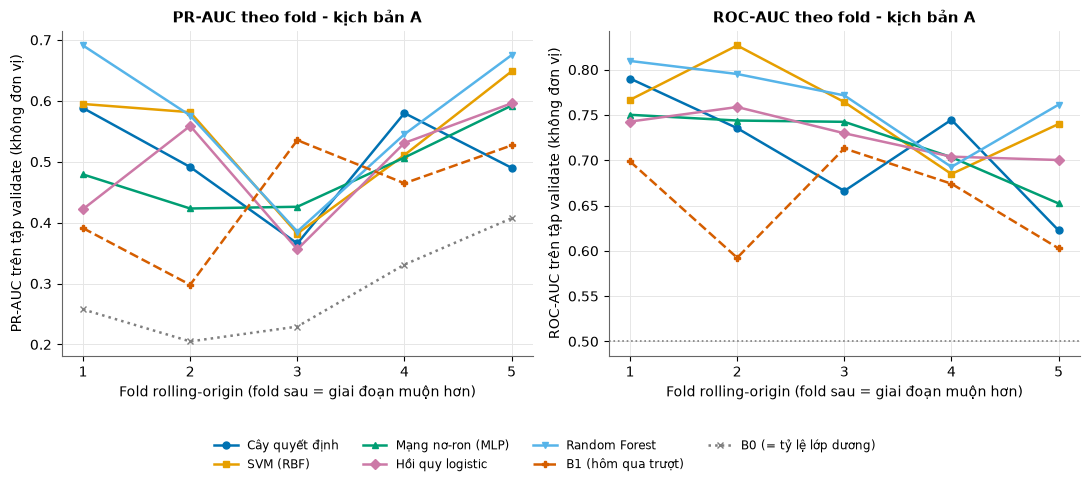

In [8]:
fig = P.plot_cv_fold_scores(folds, base_folds, "A"); plt.show()

**Nhận xét (điểm theo từng fold).**
- **PR-AUC (trái):** mọi mô hình cùng lên xuống theo fold, và đường B0 (= tỷ lệ trượt) cho thấy một phần lớn dao động là do tỷ lệ trượt thay đổi. Fold 3 là fold khó: các mô hình tụt về khoảng 0,36–0,43, trong khi B1 lại đạt 0,535 và vượt mọi mô hình.
- **ROC-AUC (phải):** không phụ thuộc tỷ lệ trượt, và cho thấy **chất lượng xếp hạng giảm dần về cuối train** ở hầu hết mô hình (Random Forest từ khoảng 0,81 ở fold 1 xuống khoảng 0,76 ở fold 5; cây quyết định từ 0,79 xuống 0,62). Giai đoạn gần test khó dự báo hơn giai đoạn đầu.
- Một khác biệt giữa hai mô hình nhỏ hơn biên độ dao động này thì khó có ý nghĩa.

### Kịch bản B (độ nhạy)
Kịch bản B thêm `incentive`, `over_time`, `no_of_style_change`, là các biến chưa rõ có được biết trước ca hay không (nguồn UCI không nêu thời điểm ghi nhận). Bảng dưới cho thấy kết quả thay đổi bao nhiêu nếu được phép dùng chúng.

In [9]:
fmt(summ, "B")

,PR-AUC,ROC-AUC,F2,Recall,Precision
mo_hinh,,,,,
Cây quyết định,0.486 ± 0.100,0.737 ± 0.032,0.611 ± 0.121,0.675 ± 0.165,0.459 ± 0.063
SVM (RBF),0.566 ± 0.101,0.776 ± 0.028,0.612 ± 0.088,0.664 ± 0.140,0.488 ± 0.056
Mạng nơ-ron (MLP),0.495 ± 0.101,0.719 ± 0.058,0.245 ± 0.079,0.217 ± 0.071,0.530 ± 0.155
Hồi quy logistic,0.579 ± 0.085,0.770 ± 0.042,0.598 ± 0.126,0.635 ± 0.158,0.497 ± 0.062
Random Forest,0.590 ± 0.127,0.793 ± 0.030,0.621 ± 0.120,0.658 ± 0.148,0.525 ± 0.101
B0 (không cảnh báo),0.286 ± 0.083,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
B1 (hôm qua trượt),0.443 ± 0.100,0.656 ± 0.055,0.488 ± 0.090,0.486 ± 0.092,0.496 ± 0.082
B2 (mọi tổ finishing),0.455 ± 0.085,0.713 ± 0.055,0.528 ± 0.098,0.585 ± 0.128,0.401 ± 0.115


**Nhận xét (kịch bản B).**
- So với A, PR-AUC CV tăng ở 4/5 mô hình nhưng phần lớn tăng ít: Random Forest +0,015, SVM +0,023, MLP +0,009, cây quyết định giảm 0,017. Riêng Logistic tăng rõ (+0,086, từ 0,493 lên 0,579).
- Các mức tăng này đều nhỏ hơn độ lệch chuẩn qua fold, nên không đủ để nói ba biến thêm vào thật sự giúp dự báo.
- MLP ở kịch bản B có Recall chỉ 0,217 ở ngưỡng mặc định: đây là ảnh hưởng của ngưỡng 0,5 khi không có `class_weight`, không phải dấu hiệu MLP xếp hạng kém (PR-AUC của nó vẫn 0,495).

## 3. Đánh giá test (một lần)
Mỗi mô hình được `fit` lại trên **toàn bộ train** với siêu tham số đã chọn, rồi dự báo 12 ngày test. Mọi mô hình đều được báo cáo để so sánh, nhưng lựa chọn mô hình chính đã được chốt ở mục 2 (trên CV) và không thay đổi theo kết quả test.

In [10]:
test_preds = []
for s in sel:
    for m in PL.MODEL_NAMES:
        _, p = E.fit_final_and_predict_test(m, s, sel[s]["best"][m], train, test)
        test_preds.append(p)
test_preds = pd.concat(test_preds + [E.baseline_test(test)], ignore_index=True)
tm = E.metrics_from_predictions(test_preds, test)
tm.round(3)

,scenario,model,n,prevalence,average_precision,roc_auc,f2,recall,precision
0,A,DecisionTree,254,0.268,0.609,0.799,0.652,0.809,0.367
1,A,SVM_RBF,254,0.268,0.546,0.773,0.641,0.721,0.445
2,A,MLP,254,0.268,0.569,0.730,0.539,0.529,0.581
3,A,Logistic,254,0.268,0.583,0.805,0.714,0.794,0.509
4,A,RandomForest,254,0.268,0.690,0.822,0.702,0.809,0.458
5,B,DecisionTree,254,0.268,0.535,0.790,0.702,0.838,0.425
6,B,SVM_RBF,254,0.268,0.546,0.804,0.691,0.765,0.500
7,B,MLP,254,0.268,0.572,0.776,0.489,0.471,0.582
8,B,Logistic,254,0.268,0.597,0.797,0.737,0.809,0.545
9,B,RandomForest,254,0.268,0.611,0.824,0.748,0.838,0.523


**Nhận xét.**
- Random Forest (kịch bản A) có PR-AUC test cao nhất, 0,690, và ROC-AUC 0,822.
- **B2 "mọi tổ finishing" rất mạnh trên test:** PR-AUC 0,592, cao hơn SVM (0,546), MLP (0,569) và Logistic (0,583), xấp xỉ cây quyết định (0,609). Một quy tắc không cần học máy đã ngang phần lớn mô hình. Đây là điểm cần nói thẳng trong phần khuyến nghị.
- PR-AUC test của hầu hết mô hình **cao hơn** CV (Random Forest 0,690 so với 0,574), dù tỷ lệ trượt của test (26,8%) gần với trung bình các fold (28,6%). Với chỉ 12 ngày, một con số test đơn lẻ dao động rất mạnh; hai mục dưới đo độ dao động đó.

### Khoảng tin cậy bootstrap theo ngày cho PR-AUC test
Test chỉ có 12 ngày. Để biết con số test chắc chắn đến đâu, lấy mẫu lại **theo ngày** (chọn ngẫu nhiên 12 ngày có hoàn lại, giữ nguyên mọi tổ của mỗi ngày được chọn) 2.000 lần, tính lại PR-AUC mỗi lần. Lấy mẫu theo ngày chứ không theo dòng, vì các tổ trong cùng một ngày không độc lập với nhau.

In [11]:
from sklearn.metrics import average_precision_score

y_te, d_te = test["miss"].to_numpy(), test["date"].to_numpy()
days = np.unique(d_te)
day_rows = {d: np.flatnonzero(d_te == d) for d in days}
cands = [("A", m) for m in PL.MODEL_NAMES] + [("-", "B1"), ("-", "B2")]
scores = {m: test_preds[(test_preds.scenario == s) & (test_preds.model == m)].set_index("row_id")["score"].reindex(test["row_id"]).to_numpy()
          for s, m in cands}

rng = np.random.default_rng(SEED)
boot = {m: [] for m in scores}
for _ in range(2000):
    idx = np.concatenate([day_rows[d] for d in rng.choice(days, len(days))])
    for m, s in scores.items():
        boot[m].append(average_precision_score(y_te[idx], s[idx]))
boot = pd.DataFrame(boot)

ci = pd.DataFrame({"PR-AUC test": {m: average_precision_score(y_te, s) for m, s in scores.items()},
                   "KTC 95% dưới": boot.quantile(0.025), "KTC 95% trên": boot.quantile(0.975)})
print("PR-AUC test và khoảng tin cậy 95% (bootstrap theo ngày, 2.000 lần, kịch bản A):")
display(ci.rename(index=P.SHORT).round(3))

diff = pd.DataFrame([{"Random Forest so với": P.SHORT[m], "chenh_TB": (boot["RandomForest"] - boot[m]).mean(),
                      "KTC 95% dưới": (boot["RandomForest"] - boot[m]).quantile(0.025),
                      "KTC 95% trên": (boot["RandomForest"] - boot[m]).quantile(0.975),
                      "P(chenh > 0)": ((boot["RandomForest"] - boot[m]) > 0).mean()}
                     for m in scores if m != "RandomForest"]).set_index("Random Forest so với")
print("Chênh lệch PR-AUC test (Random Forest trừ mô hình khác):")
diff.round(3)

PR-AUC test và khoảng tin cậy 95% (bootstrap theo ngày, 2.000 lần, kịch bản A):


,PR-AUC test,KTC 95% dưới,KTC 95% trên
Cây quyết định,0.609,0.479,0.723
SVM (RBF),0.546,0.430,0.687
Mạng nơ-ron (MLP),0.569,0.421,0.730
Hồi quy logistic,0.583,0.489,0.704
Random Forest,0.690,0.554,0.801
B1 (hôm qua trượt),0.491,0.371,0.625
B2 (mọi tổ finishing),0.592,0.466,0.729


Chênh lệch PR-AUC test (Random Forest trừ mô hình khác):


,chenh_TB,KTC 95% dưới,KTC 95% trên,P(chenh > 0)
Random Forest so với,,,,
Cây quyết định,0.080,-0.001,0.145,0.974
SVM (RBF),0.138,0.077,0.222,1.000
Mạng nơ-ron (MLP),0.121,0.007,0.240,0.978
Hồi quy logistic,0.097,-0.012,0.190,0.962
B1 (hôm qua trượt),0.193,0.089,0.280,0.999
B2 (mọi tổ finishing),0.093,0.018,0.163,0.990


**Nhận xét.**
- Khoảng tin cậy rất rộng: PR-AUC test của Random Forest nằm trong khoảng **[0,55; 0,80]**, của B2 trong khoảng [0,47; 0,73]. Hai khoảng chồng lên nhau khá nhiều; con số 0,690 chỉ là một điểm trong một dải rộng.
- Xét **chênh lệch** (bootstrap cùng các ngày cho cả hai mô hình, nên phần dao động chung bị loại bớt), Random Forest hơn rõ **SVM** [+0,08; +0,22], **B1** [+0,09; +0,28] và **B2** [+0,02; +0,16]: cả ba khoảng đều không chứa 0. So với MLP thì sát ranh giới [+0,01; +0,24]; so với cây quyết định [−0,00; +0,15] và Logistic [−0,01; +0,19] thì khoảng tin cậy chứa 0, chưa đủ bằng chứng.
- Ba lưu ý khi đọc bảng này:
  1. Khoảng tin cậy chỉ phản ánh việc test chỉ có 12 ngày, **không** phản ánh độ nhạy với siêu tham số (xem mục dưới: cấu hình gần hoà cho PR-AUC test thấp hơn gần 0,10).
  2. Test đã được xem trong quá trình phát triển, nên các con số có thể hơi lạc quan.
  3. PR-AUC đo xếp hạng trên **toàn bộ** các tổ-ngày của test. Chính sách thật chỉ cảnh báo 3 tổ đứng đầu mỗi ngày; ở `05_cost`, lợi ích ròng tại k = 3 của Random Forest so với B1 **chưa** có ý nghĩa thống kê. Hai kết quả không mâu thuẫn: mô hình xếp hạng tốt hơn nói chung, nhưng ở 3 vị trí đầu mỗi ngày thì lợi thế đó chưa đủ rõ.

### Cấu hình gần hoà của mô hình chính
Trên CV, hai cấu hình đứng đầu của Random Forest gần như hoà nhau. Nếu kết quả test thay đổi nhiều giữa hai cấu hình này, con số test của mô hình chính phụ thuộc vào việc phá hoà, tức là phụ thuộc vào may rủi. Bảng dưới fit cả hai cấu hình trên toàn bộ train và đánh giá trên test, chỉ để báo cáo.

In [12]:
tie = RA.stage_near_tie(train, test, sel, "RandomForest", tm)
tie.round(4)

[  86.7s] Kiểm tra cấu hình gần hoà của mô hình chính trên test


,model,cv_rank,params,cv_pr_auc_mean,test_pr_auc,test_roc_auc
0,RandomForest,1,"{'clf__max_depth': 4, 'clf__min_samples_leaf': 3}",0.5745,0.6899,0.8222
1,RandomForest,2,"{'clf__max_depth': 8, 'clf__min_samples_leaf': 2}",0.5740,0.5944,0.8128


**Nhận xét.**
- Hai cấu hình chỉ cách nhau 0,0005 PR-AUC trên CV (0,5745 so với 0,5740), nghĩa là trên train không phân biệt được chúng.
- Trên test, cấu hình hạng 1 (sâu 4 tầng) đạt 0,690, cấu hình hạng 2 (sâu 8 tầng) chỉ đạt 0,594: chênh gần 0,10. Như vậy **con số 0,690 phụ thuộc nhiều vào việc phá hoà**. Với cấu hình hạng 2, Random Forest không còn hơn B2 (0,592) trên test.
- Kết luận cho báo cáo: không nên trích riêng con số 0,690 như "độ chính xác của mô hình". Nên dựa vào CV (0,574 ± 0,123) và khoảng tin cậy bootstrap ở trên.

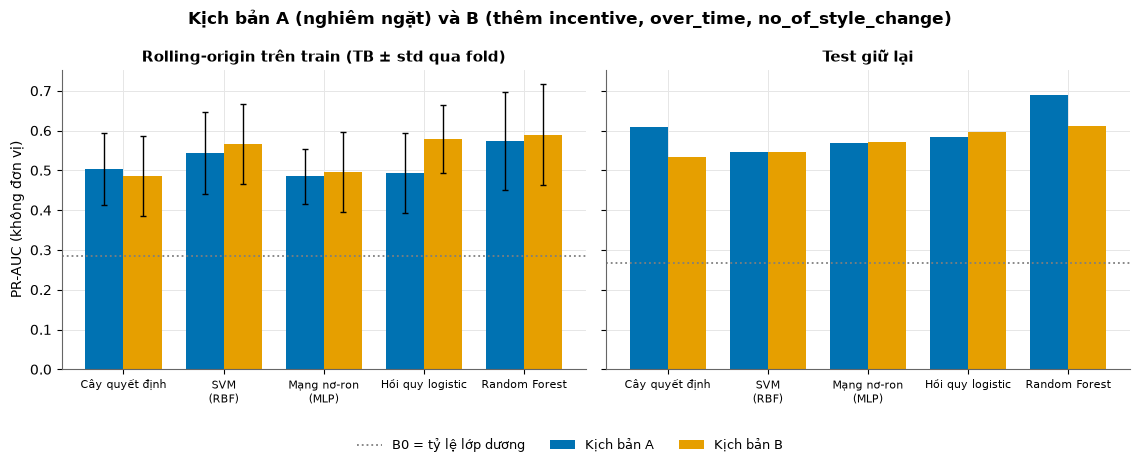

In [13]:
fig = P.plot_scenario_ab(summ, tm); plt.show()

**Nhận xét (kịch bản A và B).**
- Trên CV (trái), B cao hơn A ở 4/5 mô hình, nhưng thanh sai số chồng lên nhau gần hết.
- Trên test (phải), B **không** tốt hơn A: Random Forest B thấp hơn A (0,611 so với 0,690), cây quyết định cũng vậy (0,535 so với 0,609); ba mô hình còn lại gần như bằng nhau.
- Không có bằng chứng rằng `incentive`, `over_time`, `no_of_style_change` giúp dự báo ngoài mẫu. Điều này ủng hộ việc dùng kịch bản A, vốn an toàn hơn về rò rỉ, làm kịch bản chính.

## 4. Tổng kết

| Câu hỏi | Trả lời | Mức chắc chắn |
|---|---|---|
| Mô hình nào tốt nhất trên CV? | Random Forest (PR-AUC 0,574 ± 0,123), SVM sát sau (0,544) | Hơn SVM không chắc (4/5 fold, chênh 0,031) |
| Mô hình có hơn baseline không? | Hơn B0, B1, B2 về PR-AUC trung bình; hơn B2 ở 5/5 fold | B1 có fold vượt mô hình; xem thêm lợi ích ròng ở `05_cost` |
| Kết quả test thế nào? | Random Forest 0,690, cao nhất; B2 0,592 ngang nhiều mô hình | Khoảng tin cậy rộng; con số 0,690 nhạy với việc phá hoà |
| Kịch bản B có giúp không? | Tăng nhẹ trên CV, không tăng trên test | Giữ A làm kịch bản chính |

Các điểm cần nêu trong phần giới hạn: test chỉ 12 ngày và đã được xem trong quá trình phát triển; độ lệch chuẩn qua fold cùng cỡ với chênh lệch giữa các mô hình; F2/Recall/Precision ở ngưỡng mặc định không đại diện cho chính sách cảnh báo thật.